In [1]:
import time
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from skopt import BayesSearchCV
from src.utils import logger as log
from src.config import PROJECT_PATH

logger = log.LOGGER
config = log.CONFIG

plt.style.use("ggplot")
rng = np.random.default_rng(123)

PARAMS = {
    "CLASES": ["sano", "deriva", "fallo_duro"],
    "ROLLING_WINDOW": 5,
    "FEATURES": ["ltA_medido", "ltB_medido", "lt_residual", "residual_roll_mean", "residual_slope"],
    "UMBRAL_BASELINE": 0.15
}

In [2]:
def cargar_y_preparar(path_telemetria: str) -> pd.DataFrame:
    logger.info(f"Cargando telemetría desde: {path_telemetria}")
    tel = pd.read_csv(path_telemetria)

    def clase(row):
        if row["sensorA_fallo"] or row["sensorB_fallo"]: return 2
        if row["sensorA_deriva_activa"] or row["sensorB_deriva_activa"]: return 1
        return 0

    tel = tel.sort_values("t").reset_index(drop=True)
    tel["label"] = tel.apply(clase, axis=1)

    tel["residual_roll_mean"] = tel["lt_residual"].rolling(PARAMS["ROLLING_WINDOW"],
                                                           min_periods=1).mean()
    tel["residual_slope"] = tel["lt_residual"].diff(PARAMS["ROLLING_WINDOW"]).fillna(0) / PARAMS[
        "ROLLING_WINDOW"]

    return tel


def dividir_train_test(tel: pd.DataFrame, path_episodios: str, n_episodios_prueba: int = 2):
    ep = pd.read_csv(path_episodios).sort_values("inicio_t")
    episodios_prueba = ep.iloc[-n_episodios_prueba:]
    corte_t = episodios_prueba["inicio_t"].min()

    train = tel[tel["t"] < corte_t]
    test = tel[tel["t"] >= corte_t]

    logger.info(f"División temporal: {len(train)} train | {len(test)} test")
    return train, test


def graficar_boxplots_cv(busquedas):
    """
    Grafica la distribución de los scores en los diferentes folds
    para evaluar la estabilidad de cada método de búsqueda.
    """
    datos = []
    for nombre, searcher in busquedas.items():
        # Obtenemos los resultados de la validación cruzada
        cv_res = searcher.cv_results_
        best_idx = searcher.best_index_

        # Iteramos sobre la cantidad de splits (folds) del modelo
        n_splits = searcher.n_splits_
        for i in range(n_splits):
            score = cv_res[f'split{i}_test_score'][best_idx]
            datos.append({'Modelo': nombre, 'Fold': i, 'Accuracy': score})

    df_plot = pd.DataFrame(datos)

    plt.figure(figsize=(10, 6))
    sns.boxplot(x='Modelo', y='Accuracy', data=df_plot, palette="Set2", width=0.5)
    sns.stripplot(x='Modelo', y='Accuracy', data=df_plot, color="black", alpha=0.6, jitter=True)
    plt.title('Estabilidad del Mejor Modelo en Validación Cruzada (K-Folds)', fontsize=14)
    plt.ylabel('Accuracy en CV')
    plt.xlabel('Estrategia de Búsqueda')
    plt.tight_layout()
    file_figures = Path(config.paths.reports.figures) / "boxplots_cv.png"
    if not file_figures.exists():
        from src.config import PROJECT_PATH
        file_figures = PROJECT_PATH / config.paths.reports.figures / "boxplots_cv.png"
    plt.savefig(file_figures, dpi=150, bbox_inches="tight")
    plt.show()


def graficar_coordenadas_paralelas(busquedas):
    """
    Genera gráficos de coordenadas paralelas con Plotly para evaluar
    qué combinaciones de hiperparámetros dan mejores resultados.
    """
    for nombre, searcher in busquedas.items():
        cv_res = searcher.cv_results_
        df_cv = pd.DataFrame(cv_res['params'])
        df_cv['mean_test_score'] = cv_res['mean_test_score']

        # Convertimos variables categóricas a numéricas para poder plotearlas
        if 'criterion' in df_cv.columns:
            df_cv['criterion_num'] = df_cv['criterion'].map({'gini': 0, 'entropy': 1})
            df_cv = df_cv.drop(columns=['criterion'])

        fig = px.parallel_coordinates(
            df_cv,
            color="mean_test_score",
            dimensions=df_cv.columns,
            title=f"Coordenadas Paralelas de Hiperparámetros - {nombre}",
            color_continuous_scale=px.colors.diverging.Tealrose
        )

        file_figures = PROJECT_PATH / config.paths.reports.figures / f"coordenadas_paralelas_{nombre}.html"
        fig.write_html(file_figures)
        fig.show()


def graficar_matriz_confusion(y_test, y_pred, path_salida):
    """Genera y guarda la matriz de confusión del mejor modelo."""
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=PARAMS["CLASES"], yticklabels=PARAMS["CLASES"],
                linewidths=.5, square=True)
    plt.title('Matriz de Confusión - BayesSearchCV', size=15)
    plt.ylabel('Etiqueta Real (Verdad de Terreno)', size=12)
    plt.xlabel('Predicción del Modelo', size=12)
    plt.tight_layout()
    plt.savefig(path_salida, dpi=150, bbox_inches="tight")
    plt.close()


def graficar_residual_con_clases(tel: pd.DataFrame, path_salida):
    """Genera y guarda el gráfico de residual vs tiempo coloreado por clases."""
    colores = {0: "#2ecc71", 1: "#f2a02f", 2: "#e74c3c"}
    fig, ax = plt.subplots(figsize=(9, 4))

    # Línea base del residual
    ax.plot(tel["t"], tel["lt_residual"], color="#333333", linewidth=0.8, zorder=1)

    # Puntos de dispersión coloreados por clase
    for c, color in colores.items():
        sub = tel[tel["label"] == c]
        if not sub.empty:
            ax.scatter(sub["t"], sub["lt_residual"], color=color, s=8, label=PARAMS["CLASES"][c],
                       zorder=2)

    # Umbral de alarma
    ax.axhline(PARAMS["UMBRAL_BASELINE"], color="#999999", linestyle=":", linewidth=1,
               label=f"Umbral alarma ({PARAMS['UMBRAL_BASELINE']} m)")

    ax.set_xlabel("Tiempo simulado (s)")
    ax.set_ylabel("Residual |LT-A − LT-B| (m)")
    ax.set_title("Comportamiento Físico: Residual de sensores vs. Clase Real")
    ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(path_salida, dpi=130)
    plt.close(fig)

In [3]:
def main():
    file_path = Path(config.paths.data.raw) / "telemetria.csv"
    if not file_path.exists():
        from src.config import PROJECT_PATH
        file_path = PROJECT_PATH / config.paths.data.raw / "telemetria.csv"
    ep_path = Path(config.paths.data.raw) / "episodios.csv"
    if not ep_path.exists():
        from src.config import PROJECT_PATH
        ep_path = PROJECT_PATH / config.paths.data.raw / "episodios.csv"

    df_tel = cargar_y_preparar(file_path)
    train, test = dividir_train_test(df_tel, ep_path, n_episodios_prueba=2)

    X_train, y_train = train[PARAMS["FEATURES"]], train['label']
    X_test, y_test = test[PARAMS["FEATURES"]], test['label']

    rf = RandomForestClassifier(random_state=42)
    param_grid = {
        'n_estimators': np.arange(10, 200, 20),
        'max_depth': [10, 20],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2],
        'criterion': ['gini', 'entropy']
    }

    busquedas = {
        "GridSearchCV": GridSearchCV(rf, param_grid, cv=5, n_jobs=-1, scoring='accuracy'),
        "RandomizedSearchCV": RandomizedSearchCV(rf, param_grid, cv=5, n_jobs=-1,
                                                 scoring='accuracy', n_iter=15, random_state=42),
        "BayesSearchCV": BayesSearchCV(rf, param_grid, cv=5, n_jobs=-1, scoring='accuracy',
                                       n_iter=20, random_state=42)
    }

    historial_metricas = []

    for nombre, searcher in busquedas.items():
        logger.info(f"\n--- Ejecutando {nombre} ---")
        t0 = time.time()
        searcher.fit(X_train, y_train)
        t_fit = time.time() - t0

        best_model = searcher.best_estimator_
        y_pred = best_model.predict(X_test)
        logger.info("Mejores hiperparámetros encontrados: \n%s", searcher.best_params_)
        logger.info("Mejor exactitud durante la validación cruzada: %.2f%%", searcher.best_score_ * 100)

        # Métricas generales
        acc = metrics.accuracy_score(y_test, y_pred)

        # Métrica específica: Recall para 'fallo_duro' (clase 2)
        if (y_test == 2).sum() > 0:
            recall_fallo = ((y_pred == 2) & (y_test == 2)).sum() / (y_test == 2).sum()
        else:
            recall_fallo = 0.0

        logger.info(
            f"Tiempo: {t_fit:.2f}s | Acc Test: {acc:.4f} | Recall Fallo Duro: {recall_fallo:.4f}")
        historial_metricas.append({
            'Modelo': nombre,
            'Accuracy': acc,
            'Recall (Fallo Duro)': recall_fallo,
            'Tiempo (s)': t_fit
        })
        logger.info("Reporte de Clasificación Detallado:")
        report = metrics.classification_report(y_test, y_pred, output_dict=True)
        df_report = pd.DataFrame(report).transpose()

        # redondear y ordenar
        df_report = df_report.round(3)
        logger.info("\n%s", df_report)

    # Mostrar gráficos comparativos
    logger.info("Generando Boxplots de Validación Cruzada...")
    graficar_boxplots_cv(busquedas)

    logger.info("Generando Gráficos de Coordenadas Paralelas...")
    graficar_coordenadas_paralelas(busquedas)

    # Extraemos el mejor modelo (BayesSearchCV) para sacar su matriz de confusión
    mejor_modelo = busquedas["BayesSearchCV"].best_estimator_
    y_pred_final = mejor_modelo.predict(X_test)

    logger.info("Generando Matriz de Confusión...")
    # ruta_matriz = str(Path(config.paths.reports.figures) / "matriz_confusion_bayes.png")
    ruta_matriz = PROJECT_PATH / config.paths.reports.figures / "matriz_confusion_bayes.png"
    graficar_matriz_confusion(y_test, y_pred_final, path_salida=ruta_matriz)

    logger.info("Generando Gráfico Residual vs Clases...")
    # ruta_residual = str(Path(config.paths.reports.figures) / "residual_vs_clases.png")
    ruta_residual = PROJECT_PATH / config.paths.reports.figures / "residual_vs_clases.png"
    graficar_residual_con_clases(df_tel, path_salida=ruta_residual)

    df_comparacion = pd.DataFrame(historial_metricas).sort_values(by='Accuracy', ascending=False)
    print("\nResumen Comparativo:")
    print(df_comparacion.to_markdown(index=False))

2026-10-11 09:30:39 [INFO] Cargando telemetría desde: D:\Proyectos\optimization-ai-labs\data\raw\telemetria.csv
2026-10-11 09:30:39 [INFO] División temporal: 286 train | 232 test
D:\Proyectos\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [10, 20] was inferred to Integer(low=10, high=20, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Categorical(categories=(10, 20), prior=None). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
D:\Proyectos\optimization-ai-labs\.venv\Lib\site-packages\skopt\space\space.py:116: UserWarning: Dimension [2, 5] was inferred to Integer(low=2, high=5, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Categorical(categories=(2, 5), prior=None). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
D:\Proyectos\optimization-a

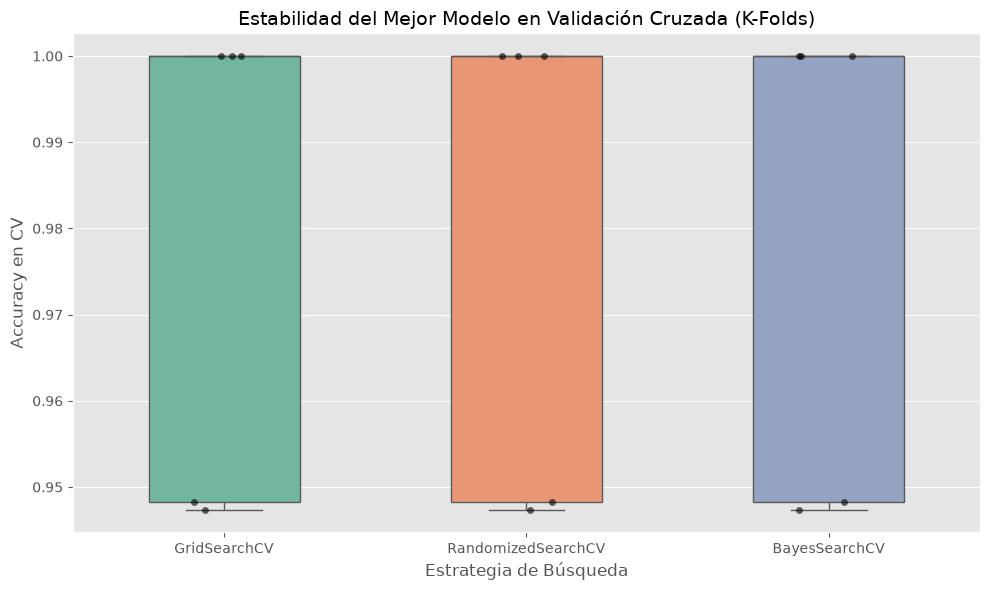

2026-10-11 09:31:59 [INFO] Generando Gráficos de Coordenadas Paralelas...


2026-10-11 09:32:01 [INFO] Generando Matriz de Confusión...
2026-10-11 09:32:02 [INFO] Generando Gráfico Residual vs Clases...



Resumen Comparativo:
| Modelo             |   Accuracy |   Recall (Fallo Duro) |   Tiempo (s) |
|:-------------------|-----------:|----------------------:|-------------:|
| GridSearchCV       |   0.935345 |                     0 |     56.1451  |
| RandomizedSearchCV |   0.935345 |                     0 |      4.04887 |
| BayesSearchCV      |   0.935345 |                     0 |     17.2572  |


In [4]:
main()